In [1]:
# 1. Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              classification_report, confusion_matrix, ConfusionMatrixDisplay)

from imblearn.over_sampling import SMOTE

import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)
RANDOM_STATE = 42
print('Libraries imported successfully.')

Libraries imported successfully.


In [2]:
# Load dataset
df = pd.read_csv('heart_failure_clinical_records_dataset.csv')
print('Shape:', df.shape)
df.head()

Shape: (299, 13)


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB


In [4]:
missing = df.isnull().sum()
print('Missing values per column:')
print(missing)
print('\nTotal missing values:', missing.sum())

Missing values per column:
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64

Total missing values: 0


DEATH_EVENT
0    203
1     96
Name: count, dtype: int64

Class proportion (%):
DEATH_EVENT
0    67.89
1    32.11
Name: count, dtype: float64


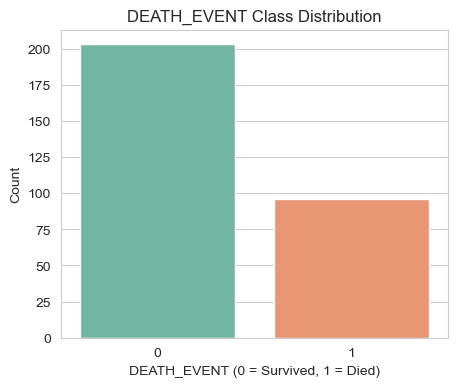

In [5]:
# Target class distribution
target_counts = df['DEATH_EVENT'].value_counts()
print(target_counts)
print('\nClass proportion (%):')
print((target_counts / len(df) * 100).round(2))

plt.figure(figsize=(5,4))
sns.countplot(x='DEATH_EVENT', data=df, palette='Set2')
plt.title('DEATH_EVENT Class Distribution')
plt.xlabel('DEATH_EVENT (0 = Survived, 1 = Died)')
plt.ylabel('Count')
plt.show()

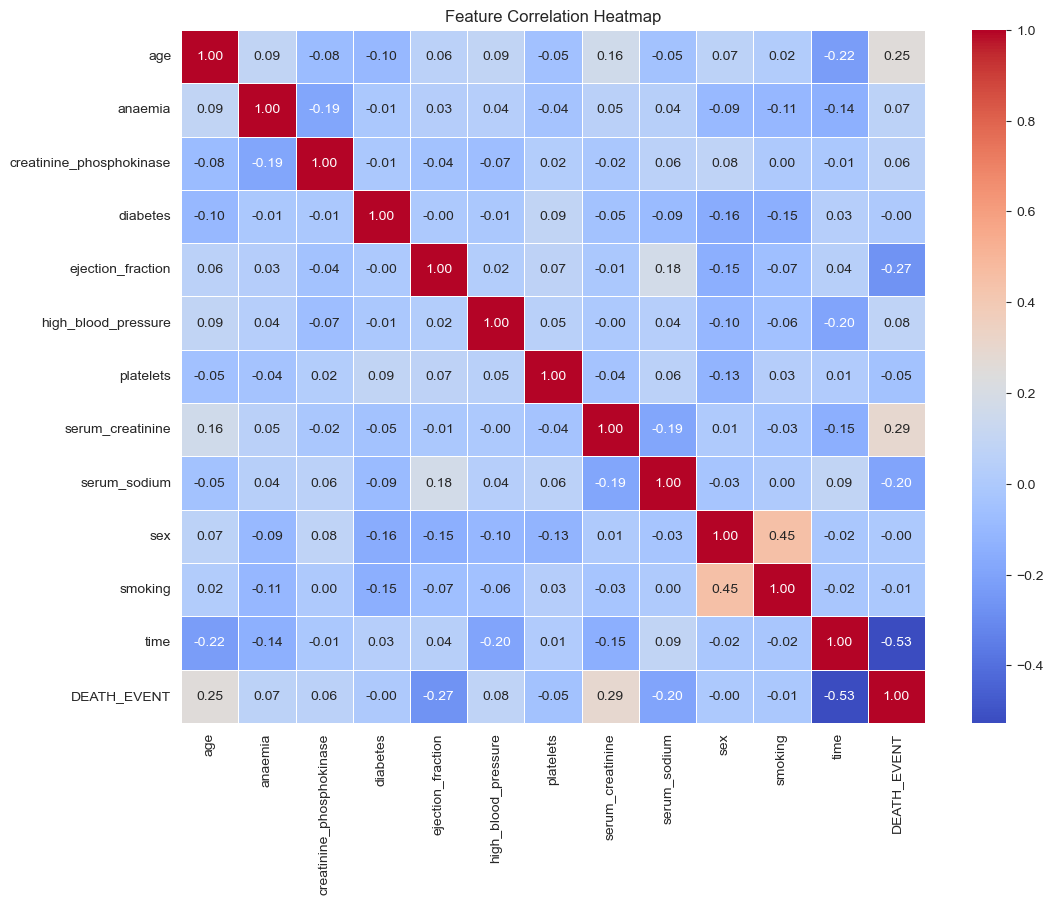

In [6]:
# Correlation heatmap to understand relationships between features
plt.figure(figsize=(12, 9))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Feature Correlation Heatmap')
plt.show()

In [7]:
# Separate features and target
X = df.drop('DEATH_EVENT', axis=1)
y = df['DEATH_EVENT']

# Train-test split (stratified to preserve class ratio in both sets)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print('Train shape:', X_train.shape, ' Test shape:', X_test.shape)

Train shape: (239, 12)  Test shape: (60, 12)


In [8]:
# Feature scaling - important for distance/gradient based models (KNN, SVM, Logistic Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)
X_train_scaled.describe().T[['mean', 'std']]

,mean,std
age,4.533798e-16,1.002099
anaemia,-4.645285e-18,1.002099
creatinine_phosphokinase,3.716228e-17,1.002099
diabetes,-4.459473e-17,1.002099
ejection_fraction,1.913857e-16,1.002099
high_blood_pressure,2.972982e-17,1.002099
platelets,-5.574342e-16,1.002099
serum_creatinine,-4.831096e-17,1.002099
serum_sodium,2.883328e-15,1.002099
sex,1.300680e-16,1.002099


In [9]:
print('Before SMOTE:', y_train.value_counts().to_dict())

smote = SMOTE(random_state=RANDOM_STATE)
X_train_bal, y_train_bal = smote.fit_resample(X_train_scaled, y_train)

print('After SMOTE :', y_train_bal.value_counts().to_dict())

Before SMOTE: {0: 162, 1: 77}
After SMOTE : {0: 162, 1: 162}


In [10]:
models = {
    'Logistic Regression': LogisticRegression(random_state=RANDOM_STATE, max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingClassifier(random_state=RANDOM_STATE),
    'KNN': KNeighborsClassifier(),
    'SVM': SVC(probability=True, random_state=RANDOM_STATE),
    'Naive Bayes': GaussianNB()
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train_bal, y_train_bal)
    y_pred = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append({'Model': name, 'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1-Score': f1})
    trained_models[name] = model

results_df = pd.DataFrame(results).sort_values('F1-Score', ascending=False).reset_index(drop=True)
results_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.816667,0.722222,0.684211,0.702703
1,Gradient Boosting,0.800000,0.666667,0.736842,0.700000
2,Decision Tree,0.783333,0.625000,0.789474,0.697674
3,Logistic Regression,0.800000,0.733333,0.578947,0.647059
4,KNN,0.750000,0.611111,0.578947,0.594595
5,Naive Bayes,0.750000,0.625000,0.526316,0.571429
6,SVM,0.733333,0.588235,0.526316,0.555556


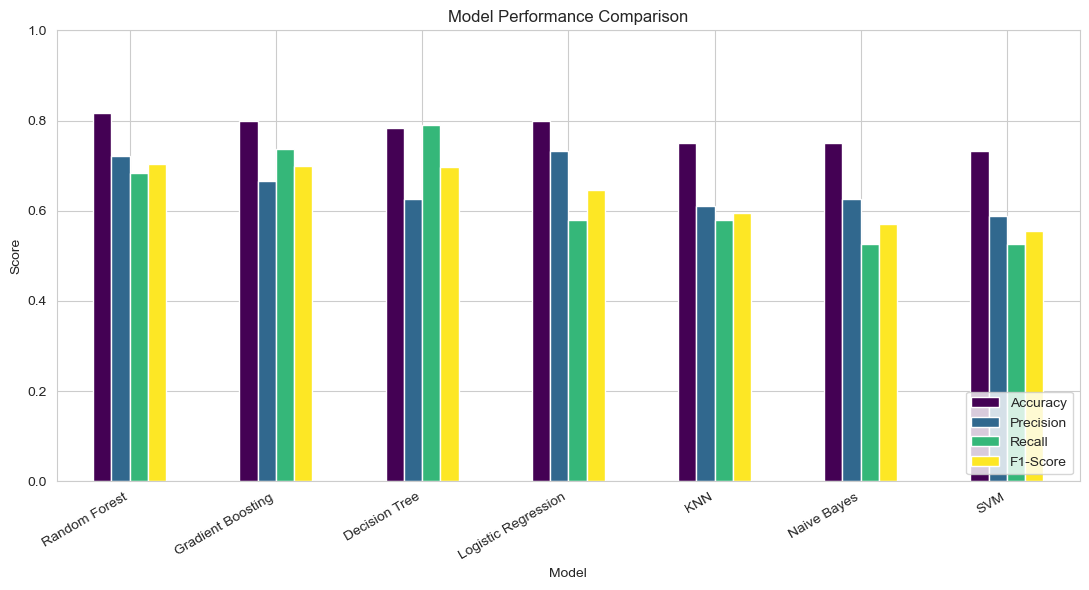

In [11]:
# Visual comparison of models
results_df.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1-Score']].plot(
    kind='bar', figsize=(11, 6), colormap='viridis'
)
plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.xticks(rotation=30, ha='right')
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

--- Logistic Regression ---
              precision    recall  f1-score   support

Survived (0)       0.82      0.90      0.86        41
    Died (1)       0.73      0.58      0.65        19

    accuracy                           0.80        60
   macro avg       0.78      0.74      0.75        60
weighted avg       0.79      0.80      0.79        60

--- Decision Tree ---
              precision    recall  f1-score   support

Survived (0)       0.89      0.78      0.83        41
    Died (1)       0.62      0.79      0.70        19

    accuracy                           0.78        60
   macro avg       0.76      0.78      0.76        60
weighted avg       0.81      0.78      0.79        60

--- Random Forest ---
              precision    recall  f1-score   support

Survived (0)       0.86      0.88      0.87        41
    Died (1)       0.72      0.68      0.70        19

    accuracy                           0.82        60
   macro avg       0.79      0.78      0.79        60
we

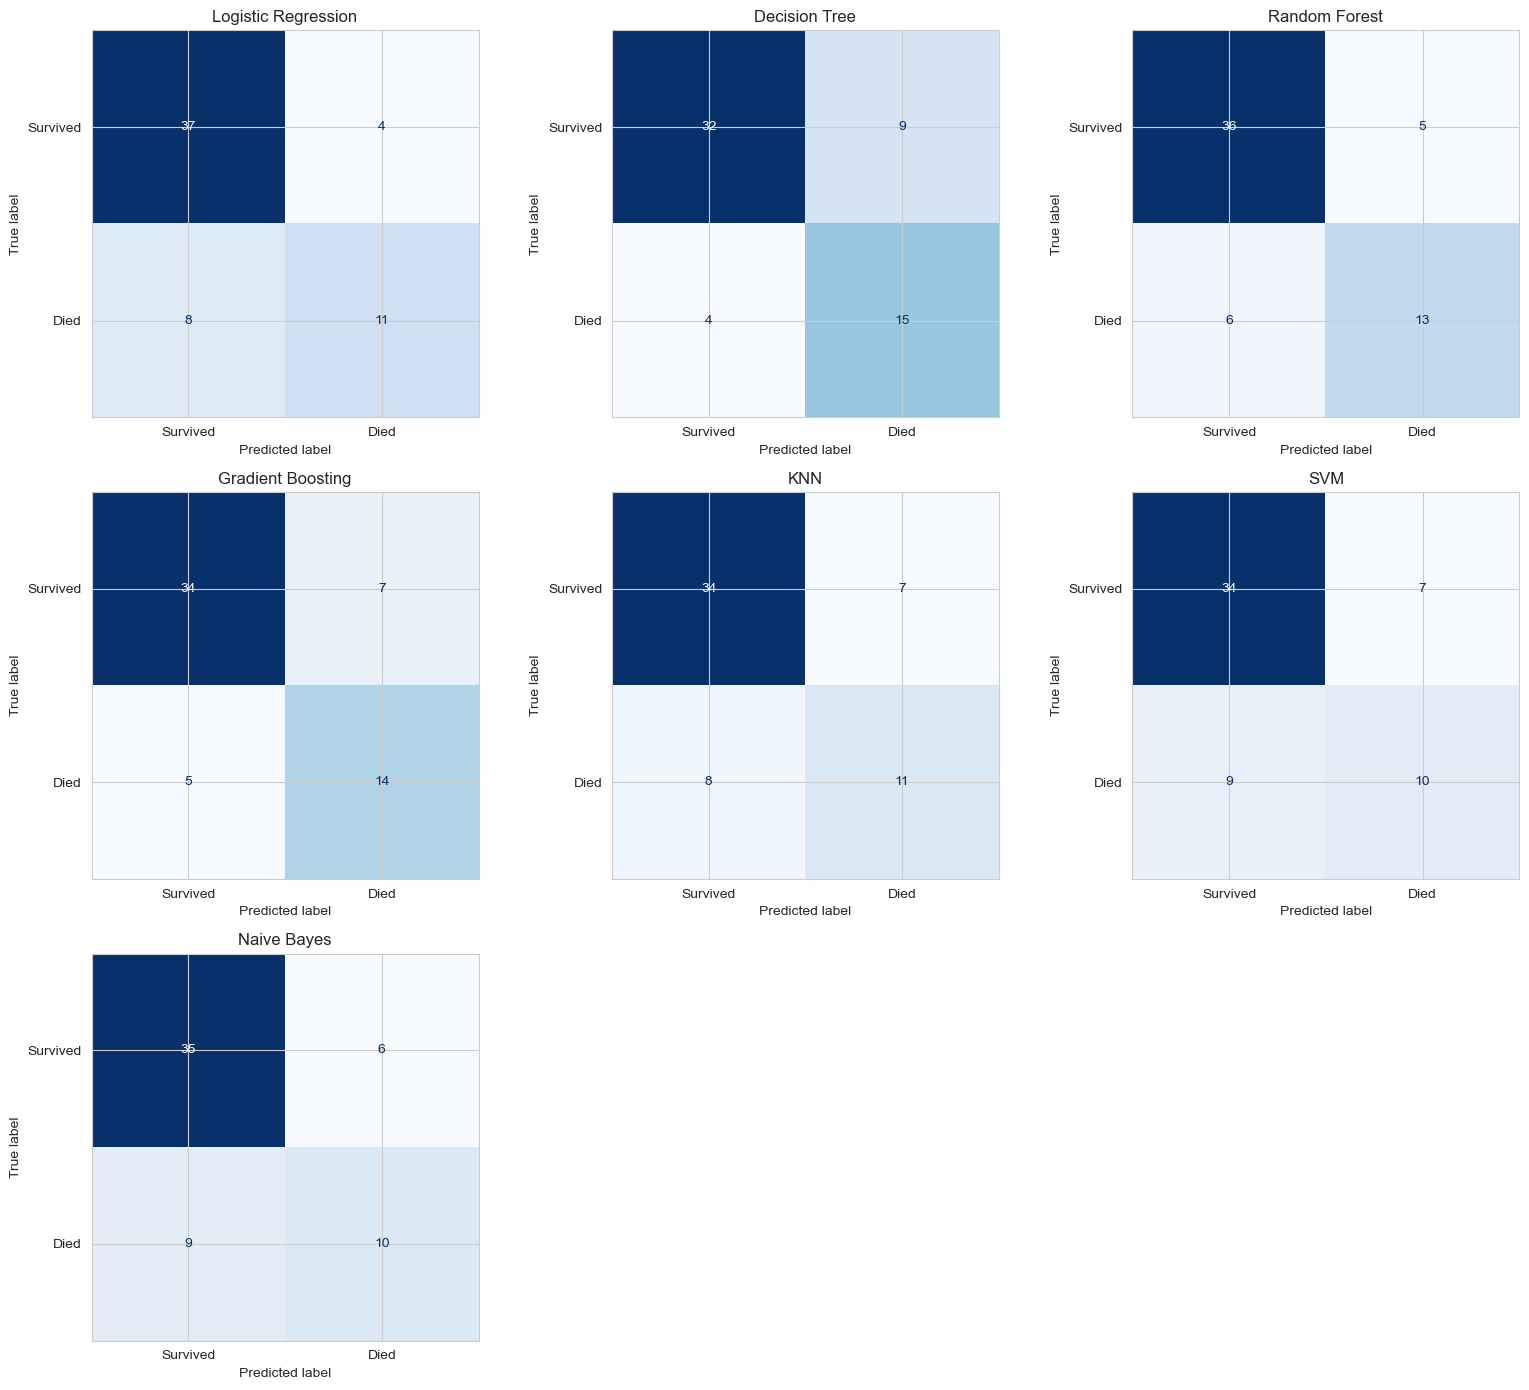

In [12]:
fig, axes = plt.subplots(3, 3, figsize=(16, 14))
axes = axes.flatten()

for i, (name, model) in enumerate(trained_models.items()):
    y_pred = model.predict(X_test_scaled)
    print(f'--- {name} ---')
    print(classification_report(y_test, y_pred, target_names=['Survived (0)', 'Died (1)']))

    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Survived', 'Died'])
    disp.plot(ax=axes[i], colorbar=False, cmap='Blues')
    axes[i].set_title(name)

for j in range(len(trained_models), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [19]:
best_model_name = results_df.iloc[0]['Model']
print('Best baseline model based on F1-Score:', best_model_name)

Best baseline model based on F1-Score: Random Forest


In [21]:
param_grids = {
    'Random Forest': {'n_estimators': [100, 200, 300], 'max_depth': [None, 5, 10, 15],
                       'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 4]},
    'Gradient Boosting': {'n_estimators': [100, 200], 'learning_rate': [0.01, 0.05, 0.1],
                           'max_depth': [2, 3, 4], 'subsample': [0.8, 1.0]},
    'SVM': {'C': [0.1, 1, 10, 100], 'gamma': ['scale', 0.01, 0.1, 1], 'kernel': ['rbf', 'linear']},
    'Logistic Regression': {'C': [0.01, 0.1, 1, 10, 100], 'penalty': ['l2'], 'solver': ['lbfgs']},
    'KNN': {'n_neighbors': [3, 5, 7, 9, 11], 'weights': ['uniform', 'distance'], 'p': [1, 2]},
    'Decision Tree': {'max_depth': [3, 5, 7, 10, None], 'min_samples_split': [2, 5, 10],
                       'criterion': ['gini', 'entropy']},
    'Naive Bayes': {'var_smoothing': np.logspace(0, -9, 10)}
}

base_estimators = {
    'Random Forest': RandomForestClassifier(random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingClassifier(random_state=RANDOM_STATE),
    'SVM': SVC(probability=True, random_state=RANDOM_STATE),
    'Logistic Regression': LogisticRegression(random_state=RANDOM_STATE, max_iter=1000),
    'KNN': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Naive Bayes': GaussianNB()
}

grid = GridSearchCV(
    estimator=base_estimators[best_model_name],
    param_grid=param_grids[best_model_name],
    cv=5, scoring='f1', n_jobs=-1
)

grid.fit(X_train_bal, y_train_bal)   # 👈 isi cell mein 'grid' define hota hai

print('Best Parameters:', grid.best_params_)
print('Best CV F1-Score :', round(grid.best_score_, 4))

Best Parameters: {'max_depth': None, 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 200}
Best CV F1-Score : 0.8967
